In [18]:
pip install ucimlrepo

## 1. Dataset Handling



In [19]:
import pandas as pd
import numpy as np
import urllib.request
import zipfile
import io

# 1. Fetch dataset directly from the UCI source URL
url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
print("Downloading dataset from UCI...")

req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
with urllib.request.urlopen(req) as response:
    zip_file = zipfile.ZipFile(io.BytesIO(response.read()))
    with zip_file.open('SMSSpamCollection') as f:
        df = pd.read_csv(f, sep='\t', names=['label', 'text'])

print(f"Initial Dataset Shape: {df.shape}")

print("\nMissing values in each column:")
print(df.isnull().sum())

df = df.drop_duplicates(subset=['text']).reset_index(drop=True)
print(f"\nShape after removing duplicates: {df.shape}")

df['label_num'] = df['label'].map({'spam': 1, 'ham': 0})

display(df.head())

Initial Dataset Shape: (5572, 2)

Missing values in each column:
label    0
text     0
dtype: int64

Shape after removing duplicates: (5169, 2)


,label,text,label_num
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


## 2. Dataset Analysis



Total Messages: 5169
Spam Messages: 653 (P(Spam) = 0.1263)
Ham Messages: 4516 (P(Ham) = 0.8737)


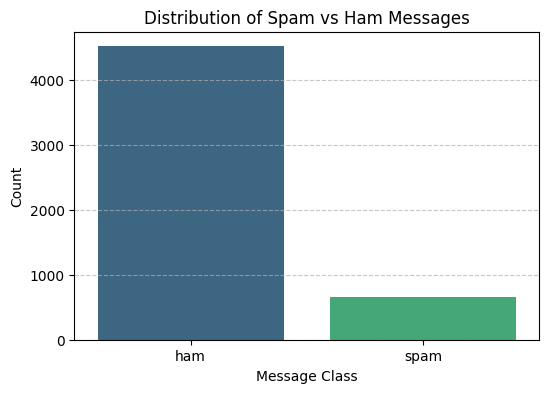

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

total_messages = len(df)
num_spam = (df['label_num'] == 1).sum()
num_ham = (df['label_num'] == 0).sum()

p_spam = num_spam / total_messages
p_ham = num_ham / total_messages

print(f"Total Messages: {total_messages}")
print(f"Spam Messages: {num_spam} (P(Spam) = {p_spam:.4f})")
print(f"Ham Messages: {num_ham} (P(Ham) = {p_ham:.4f})")

plt.figure(figsize=(6, 4))
sns.countplot(x='label', data=df, palette='viridis', hue='label', legend=False)
plt.title('Distribution of Spam vs Ham Messages')
plt.xlabel('Message Class')
plt.ylabel('Count')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

## 3. Word-Based Probability Analysis



In [21]:
import re

suspicious_words = ['free', 'prize', 'win', 'urgent', 'offer']

def contains_word(text, word):
    pattern = r'\b' + re.escape(word) + r'\b'
    return bool(re.search(pattern, text, re.IGNORECASE))

for word in suspicious_words:
    df[word] = df['text'].apply(lambda x: contains_word(x, word))

print(f"P(Spam) = {p_spam:.4f}\n")

for word in suspicious_words:
    total_word = df[word].sum()
    if total_word == 0:
        print(f"The word '{word}' was not found in any message.")
        continue

    spam_word = df[(df[word] == 1) & (df['label_num'] == 1)].shape[0]

    p_spam_given_word_empirical = spam_word / total_word

    p_word = total_word / total_messages
    p_word_given_spam = spam_word / num_spam

    p_spam_given_word_bayes = (p_word_given_spam * p_spam) / p_word

    print(f"Word: '{word}'")
    print(f"  - Total containing '{word}': {total_word}")
    print(f"  - Spam containing '{word}': {spam_word}")
    print(f"  - Empirical P(Spam | {word.capitalize()}) = {p_spam_given_word_empirical:.4f}")
    print(f"  - Bayes' Theorem Verification:")
    print(f"    * P({word.capitalize()} | Spam) = {p_word_given_spam:.4f}")
    print(f"    * P({word.capitalize()}) = {p_word:.4f}")
    print(f"    * Bayes' P(Spam | {word.capitalize()}) = {p_spam_given_word_bayes:.4f}\n")

P(Spam) = 0.1263

Word: 'free'
  - Total containing 'free': 203
  - Spam containing 'free': 148
  - Empirical P(Spam | Free) = 0.7291
  - Bayes' Theorem Verification:
    * P(Free | Spam) = 0.2266
    * P(Free) = 0.0393
    * Bayes' P(Spam | Free) = 0.7291

Word: 'prize'
  - Total containing 'prize': 73
  - Spam containing 'prize': 73
  - Empirical P(Spam | Prize) = 1.0000
  - Bayes' Theorem Verification:
    * P(Prize | Spam) = 0.1118
    * P(Prize) = 0.0141
    * Bayes' P(Spam | Prize) = 1.0000

Word: 'win'
  - Total containing 'win': 55
  - Spam containing 'win': 49
  - Empirical P(Spam | Win) = 0.8909
  - Bayes' Theorem Verification:
    * P(Win | Spam) = 0.0750
    * P(Win) = 0.0106
    * Bayes' P(Spam | Win) = 0.8909

Word: 'urgent'
  - Total containing 'urgent': 62
  - Spam containing 'urgent': 57
  - Empirical P(Spam | Urgent) = 0.9194
  - Bayes' Theorem Verification:
    * P(Urgent | Spam) = 0.0873
    * P(Urgent) = 0.0120
    * Bayes' P(Spam | Urgent) = 0.9194

Word: 'offer'


## 4. Random Variable Analysis


In [22]:
p = p_spam
expectation_y = p
variance_y = p * (1 - p)

print(f"For Random Variable Y:")
print(f"Expectation E(Y) = {expectation_y:.4f}")
print(f"Variance Var(Y) = {variance_y:.4f}")

For Random Variable Y:
Expectation E(Y) = 0.1263
Variance Var(Y) = 0.1104


## 5 & 6. Data Preparation and Model Building



In [23]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    df['text'],
    df['label_num'],
    test_size=0.2,
    random_state=42,
    stratify=df['label_num']
)

vectorizer = CountVectorizer(stop_words='english')
X_train = vectorizer.fit_transform(X_train_raw)
X_test = vectorizer.transform(X_test_raw)

model = MultinomialNB()
model.fit(X_train, y_train)

print("Model trained successfully.")

Model trained successfully.


## 7. Model Evaluation

Let's measure performance metrics, including accuracy, a classification report, and build the confusion matrix.

Accuracy Score: 0.9836

Classification Report:
              precision    recall  f1-score   support

         Ham       0.99      0.99      0.99       903
        Spam       0.96      0.91      0.93       131

    accuracy                           0.98      1034
   macro avg       0.97      0.95      0.96      1034
weighted avg       0.98      0.98      0.98      1034



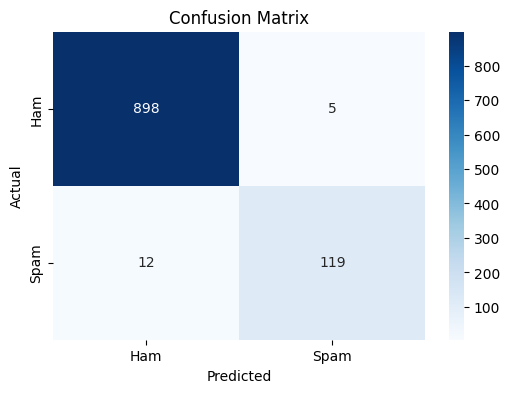


Analysis:
- Genuine messages incorrectly classified as Spam (False Positives): 5
- Spam messages incorrectly classified as Genuine (False Negatives): 12


In [24]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)
report = classification_report(y_test, y_pred, target_names=['Ham', 'Spam'])

print(f"Accuracy Score: {accuracy:.4f}\n")
print("Classification Report:")
print(report)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
plt.title('Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"\nAnalysis:")
print(f"- Genuine messages incorrectly classified as Spam (False Positives): {fp}")
print(f"- Spam messages incorrectly classified as Genuine (False Negatives): {fn}")

## 8. Demo



In [25]:
def predict_sms(message):
    vect_message = vectorizer.transform([message])

    prediction = model.predict(vect_message)[0]

    probabilities = model.predict_proba(vect_message)[0]

    pred_label = "Spam" if prediction == 1 else "Ham"

    print(f"Input Message: \"{message}\"")
    print(f"Prediction: {pred_label}")
    print(f"P(Spam | Message) = {probabilities[1]:.4f}")
    print(f"P(Ham | Message) = {probabilities[0]:.4f}\n")

test_msg = "Congratulations! You have won a free prize. Claim now."
predict_sms(test_msg)

predict_sms("Hey, how are you?")

Input Message: "Congratulations! You have won a free prize. Claim now."
Prediction: Spam
P(Spam | Message) = 1.0000
P(Ham | Message) = 0.0000

Input Message: "Hey, how are you?"
Prediction: Ham
P(Spam | Message) = 0.0144
P(Ham | Message) = 0.9856

